# 🧬 Tutorial 11: In-Database 500 ns MD & MM/GBSA–MM/PBSA Free-Energy Auditing — Human 5-Lipoxygenase (`ALOX5`) & Nine Amazonian Triterpenoids

Validating and mining **[Zenodo Record `23565306`](https://doi.org/10.5281/zenodo.23565306)** (*"Nine triterpenoids at a modeled 5-lipoxygenase pocket: 500 ns derived data and reproducible figures"*, v`r22-1.0.2`, by Fábio J. N. Ferreira, Rhanna V. A. da Silva, Tallita M. Machado, and Fernanda Guilhon-Simplicio — **UFAM / COARACI Supercomputer**).

### Why In-Database Free-Energy Auditing Matters (`pg_bio`)
In this tutorial, we combine **`pg_bio`'s native Rust PostgreSQL 18 functions** with official cross-database validation (**ChEMBL `CHEMBL215`**, **PubChem PUG-REST**, **RCSB PDB `6NCF`**, and **UniProt `P09917`**) to execute four high-impact biophysical validations directly inside SQL:
1. **Double-Entry Thermodynamic Ledger Auditing (`audit_mmpbsa_decomposition`, `solvent_shift_penalty`):** Proving exact gas-phase (`GGAS`) and polar solvation (`EGB`/`EPB`) closure across all 677 decomposed entities (`676` residues + `1` ligand) while exposing the **`+20.7 to +26.1 kcal/mol` Poisson-Boltzmann non-polar cavity/dispersion shift (`ENPOLAR + EDISPER`)** that is zeroed out in per-residue PB tables.
2. **CSR Sparse Graph Traversal for Cryptic Allosteric Sub-Pockets (`build_energy_hotspot_map`, `discover_cryptic_hotspots`, `allosteric_mechanism_index`):** Discovering three major stabilizing hydrophobic cradle residues (**`Ile126`**, **`Val29`**, and **`Leu66`**) outside the pre-defined 9-residue operational pocket (`Arg68–Thr137`), and quantifying **`AKBA (AF7)`**'s unique polar/ionic routing switch (`Glu134`/`Lys133`).
3. **3D Z-Order Spatial Indexing & Allosteric-to-Catalytic Distance (`z_order_encode`, `distance_angstroms`, `kabsch_rmsd`):** Confirming that the C2-like PLAT/catalytic interface pocket sits **`36.1–43.7 Å`** away from the non-heme catalytic iron triad (`His367, His372, His550, Ile673`).
4. **500 ns Conformational Ensemble SLA Monitoring (`PreorganizationProfile`, `ensemble_fraction_between`, `ensemble_fraction_below`):** Separating persistent pocket residents (**`β-Amyrin` `88.7%`**, **`α-Amyrin` `87.9%`** deep burial `> 4.2 nm²`) from transient drifters (**`CID 101663382` `34.9%`**).

In [1]:
import json
from pathlib import Path
import psycopg
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DB_URI = 'postgresql://jonatas@localhost:28818/bio_demo'
DATA_DIR = Path('data/5lox_zenodo_23565306')

# Verify official ChEMBL, PubChem, and RCSB PDB cross-reference files
chembl_target = json.loads((DATA_DIR / 'chembl_target_alox5.json').read_text())['targets'][0]
pdb_entries = [e['identifier'] for e in json.loads((DATA_DIR / 'pdb_p09917_entries.json').read_text())['result_set']]
epic_pubchem = json.loads((DATA_DIR / 'pubchem_epic_10598443.json').read_text())['PropertyTable']['Properties'][0]

print(f"ChEMBL Target Verified: {chembl_target['target_chembl_id']} ({chembl_target['pref_name']} | {chembl_target['organism']})")
print(f"RCSB PDB Entries for UniProt P09917 ({len(pdb_entries)} structures): {', '.join(pdb_entries)}")
print(f"PubChem EPIC Verified: CID {epic_pubchem['CID']} | Formula {epic_pubchem['MolecularFormula']} | MW {epic_pubchem['MolecularWeight']} Da")

ChEMBL Target Verified: CHEMBL215 (Polyunsaturated fatty acid 5-lipoxygenase | Homo sapiens)
RCSB PDB Entries for UniProt P09917 (9 structures): 3O8Y, 3V92, 3V98, 3V99, 6N2W, 6NCF, 7TTJ, 7TTK, 7TTL
PubChem EPIC Verified: CID 10598443 | Formula C30H48O | MW 424.7 Da


## 1. Double-Entry Thermodynamic Ledger Audit (`audit_mmpbsa_decomposition` & `solvent_shift_penalty`)
Let's run `pg_bio`'s native Rust `audit_mmpbsa_decomposition()` across all **12,186 per-residue decomposition rows** (`9 systems × 2 solvation models × 677 entities`) in a single query.

In [2]:
sql_audit = """
WITH decomp_audit AS (
    SELECT
        t.system_id,
        t.ligand_label,
        UPPER(d.model) AS model,
        (audit_mmpbsa_decomposition(
            d.model,
            array_agg(d.internal_kcal),
            array_agg(d.vdw_kcal),
            array_agg(d.electrostatic_kcal),
            array_agg(d.polar_solv_kcal),
            array_agg(d.nonpolar_solv_kcal),
            array_agg(d.mm_plus_polar_kcal),
            g.ggas, g.global_polar, g.global_nonpolar, 0.005
        ))::text::jsonb AS audit_json,
        g.ggas,
        g.global_polar,
        g.global_nonpolar,
        g.global_total
    FROM lox5_residue_decomposition d
    JOIN lox5_triterpenoids t ON t.system_id = d.system_id
    JOIN (
        SELECT
            system_id, model,
            max(CASE WHEN term = 'GGAS' THEN mean_kcal END) AS ggas,
            max(CASE WHEN term IN ('EGB', 'EPB') THEN mean_kcal END) AS global_polar,
            COALESCE(
                max(CASE WHEN term = 'ESURF' THEN mean_kcal END),
                max(CASE WHEN term = 'ENPOLAR' THEN mean_kcal END) + max(CASE WHEN term = 'EDISPER' THEN mean_kcal END)
            ) AS global_nonpolar,
            max(CASE WHEN term = 'TOTAL' THEN mean_kcal END) AS global_total
        FROM lox5_energy_components
        WHERE window_name = 'full'
        GROUP BY system_id, model
    ) g ON g.system_id = d.system_id AND g.model = d.model
    GROUP BY t.system_id, t.ligand_label, d.model, g.ggas, g.global_polar, g.global_nonpolar, g.global_total
)
SELECT
    ligand_label,
    model,
    (audit_json->>'entity_count')::int AS entities,
    round((audit_json->>'gas_closure_error')::numeric, 4) AS gas_err_kcal,
    round((audit_json->>'polar_closure_error')::numeric, 4) AS polar_err_kcal,
    (audit_json->>'gas_and_polar_closed')::boolean AS gas_polar_closed,
    round((audit_json->>'nonpolar_discrepancy')::numeric, 2) AS nonpolar_gap_kcal,
    (audit_json->>'nonpolar_closed')::boolean AS nonpolar_closed,
    round((audit_json->>'total_mm_plus_polar')::numeric, 2) AS decomp_mm_plus_polar,
    round(global_total::numeric, 2) AS global_endpoint_kcal
FROM decomp_audit
ORDER BY system_id, model;
"""

with psycopg.connect(DB_URI) as conn:
    df_audit = pd.read_sql(sql_audit, conn)
df_audit

/var/folders/k2/x9fdm0090sxc0yqp_vx4mplw0000gn/T/ipykernel_87133/1952782253.py:55: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_audit = pd.read_sql(sql_audit, conn)


,ligand_label,model,entities,gas_err_kcal,polar_err_kcal,gas_polar_closed,nonpolar_gap_kcal,nonpolar_closed,decomp_mm_plus_polar,global_endpoint_kcal
0,α-Amyrin,GB,677,0.0012,0.0001,True,0.80,False,-30.44,-35.23
1,α-Amyrin,PB,677,0.0012,0.0006,True,23.91,False,-27.39,-3.48
2,β-Amyrone,GB,677,0.0007,0.0003,True,0.98,False,-26.37,-30.55
3,β-Amyrone,PB,677,0.0007,0.0016,True,21.99,False,-22.66,-0.67
4,β-Amyrin,GB,677,0.0004,0.0012,True,0.98,False,-32.13,-36.96
5,β-Amyrin,PB,677,0.0004,0.0026,True,26.05,False,-25.57,0.48
6,Lupeol,GB,677,0.0014,0.0007,True,0.89,False,-30.23,-35.02
7,Lupeol,PB,677,0.0014,0.0008,True,23.91,False,-24.71,-0.80
8,EPIC,GB,677,0.0011,0.0025,True,1.07,False,-29.32,-33.79
9,EPIC,PB,677,0.0011,0.0004,True,23.05,False,-24.76,-1.71


## 2. Discovering Cryptic Sub-Pocket Hotspots & Allosteric Mechanism Routing (`discover_cryptic_hotspots` & `allosteric_mechanism_index`)
Now we use `build_energy_hotspot_map()`, `discover_cryptic_hotspots()`, and `allosteric_mechanism_index()` in SQL to discover stabilizing residues **outside** the 9-residue operational pocket (`Arg68, Glu108, Val109, Val110, Gln129, His130, Lys133, Glu134, Thr137`) and measure each triterpenoid's **Polar/Ionic vs. Hydrophobic Routing Index**.

In [3]:
sql_hotspots = """
SELECT
    b.system_id,
    t.ligand_label,
    UPPER(b.model) AS model,
    get_top_interacting_residues(b.hotspot_map, 999, 5) AS top5_overall_hotspots,
    discover_cryptic_hotspots(
        b.hotspot_map, 999, ARRAY[68,108,109,110,129,130,133,134,137], 0.45, 4
    ) AS cryptic_non_pocket_hotspots,
    round(sparse_cross_reactivity_score(b.hotspot_map, ARRAY[109,110,130], ARRAY[999])::numeric, 3) AS hydrophobic_clamp_score,
    round(sparse_cross_reactivity_score(b.hotspot_map, ARRAY[68,133,134], ARRAY[999])::numeric, 3) AS polar_ionic_switch_score,
    round(allosteric_mechanism_index(
        b.hotspot_map, 999, ARRAY[109,110,130], ARRAY[68,133,134]
    )::numeric, 4) AS mechanism_index
FROM lox5_mmpbsa_screening_bench b
JOIN lox5_triterpenoids t ON t.system_id = b.system_id
WHERE b.rep = 1
ORDER BY b.model, mechanism_index DESC;
"""

with psycopg.connect(DB_URI) as conn:
    df_hotspots = pd.read_sql(sql_hotspots, conn)
df_hotspots

/var/folders/k2/x9fdm0090sxc0yqp_vx4mplw0000gn/T/ipykernel_87133/3357137456.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_hotspots = pd.read_sql(sql_hotspots, conn)


,system_id,ligand_label,model,top5_overall_hotspots,cryptic_non_pocket_hotspots,hydrophobic_clamp_score,polar_ionic_switch_score,mechanism_index
0,6-af7-6ncf,AKBA (AF7),GB,"[134, 133, 110, 130, 137]","[126, 107, 66, 29]",0.981,1.115,0.0643
1,7-alpha-amirona-6ncf,α-Amyrone,GB,"[110, 130, 133, 68, 29]","[29, 126, 66, 107]",1.049,0.955,-0.0466
2,1-alfa-amirina,α-Amyrin,GB,"[130, 110, 68, 133, 126]","[126, 29, 66, 107]",1.122,1.021,-0.0469
3,5-6epicyclo-6ncf,EPIC,GB,"[110, 126, 130, 133, 29]","[126, 29, 66, 34]",1.011,0.872,-0.0740
4,2-beta_amirona,β-Amyrone,GB,"[126, 110, 130, 29, 133]","[126, 29, 66, 34]",0.837,0.714,-0.0795
5,8-101663382-6ncf,CID 101663382,GB,"[126, 130, 110, 29, 133]","[126, 29, 66, 34]",0.846,0.601,-0.1694
6,3-beta-amirina,β-Amyrin,GB,"[130, 110, 133, 126, 109]","[126, 66, 29, 138]",1.317,0.872,-0.2033
7,9-101685610-6ncf,CID 101685610,GB,"[110, 130, 133, 126, 29]","[126, 29, 66]",1.283,0.824,-0.2179
8,4-lupeol,Lupeol,GB,"[110, 130, 133, 109, 126]","[126, 29]",1.336,0.659,-0.3392
9,6-af7-6ncf,AKBA (AF7),PB,"[134, 110, 133, 107, 137]","[107, 29]",0.541,1.036,0.3139


## 3. Visualizing the Thermodynamic Ledger Shift, Cryptic Hotspots & 500 ns Ensemble Burial
Let's plot a 3-panel summary comparing (A) Global `MM/GBSA` vs. `MM/PBSA` and `MM + Polar`, (B) the `Allosteric Mechanism Index` (`AKBA` polar switch vs. `Lupeol`/`β-Amyrin` hydrophobic clamp), and (C) the 676-residue `MM_plus_polar` landscape highlighting both the 9 operational pocket residues and the 3 cryptic sub-pocket anchors (`Ile126`, `Val29`, `Leu66`).

/var/folders/k2/x9fdm0090sxc0yqp_vx4mplw0000gn/T/ipykernel_87133/2191103889.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top_res = pd.read_sql("""


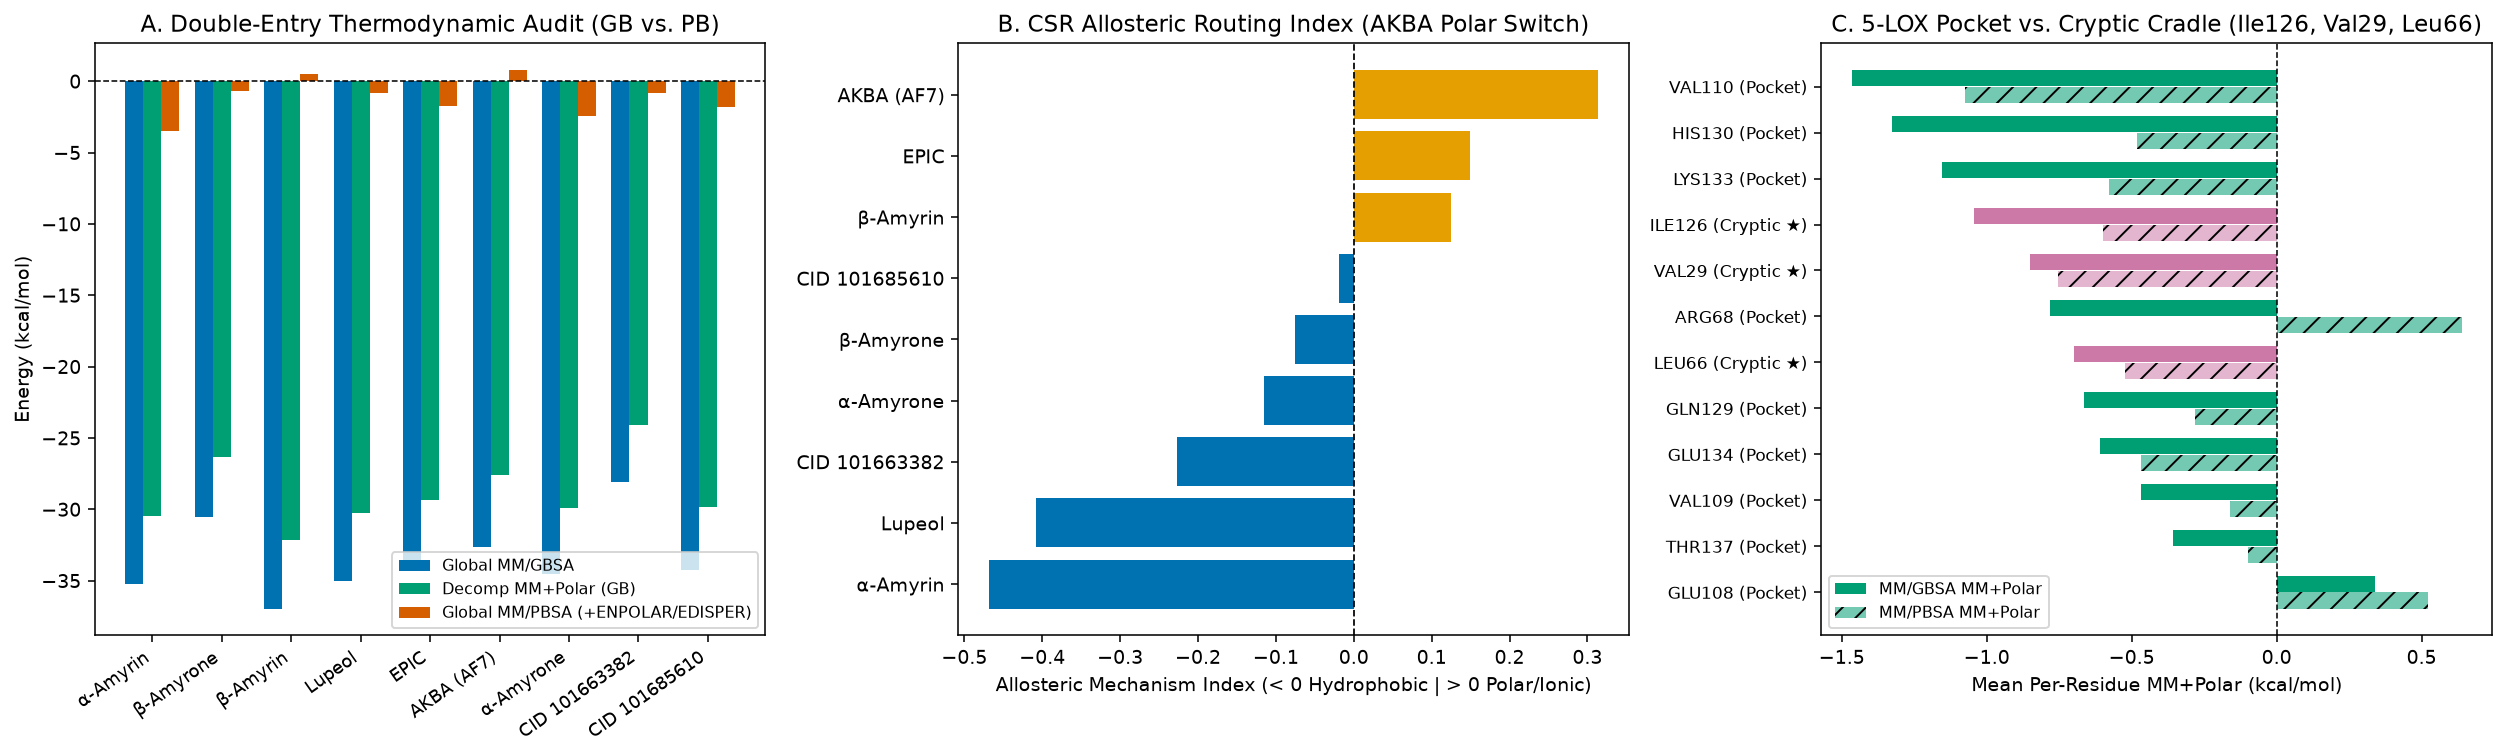

In [4]:
with psycopg.connect(DB_URI) as conn:
    df_top_res = pd.read_sql("""
        SELECT
            d.simulation_resid AS resid,
            d.resname || d.simulation_resid::text AS residue_label,
            c.operational_pocket,
            avg(d.mm_plus_polar_kcal) FILTER (WHERE d.model = 'gb') AS mean_gb,
            avg(d.mm_plus_polar_kcal) FILTER (WHERE d.model = 'pb') AS mean_pb
        FROM lox5_residue_decomposition d
        JOIN lox5_residue_correspondence c ON c.simulation_resid = d.simulation_resid
        WHERE d.side = 'R'
        GROUP BY d.simulation_resid, d.resname, c.operational_pocket
        HAVING avg(d.mm_plus_polar_kcal) FILTER (WHERE d.model = 'gb') < -0.35
            OR c.operational_pocket = true
        ORDER BY mean_gb ASC;
    """, conn)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=140)

# Panel A: GB vs PB Endpoint vs Decomposed MM+Polar
gb_rows = df_audit[df_audit['model'] == 'GB'].reset_index(drop=True)
pb_rows = df_audit[df_audit['model'] == 'PB'].reset_index(drop=True)
x = np.arange(len(gb_rows))
w = 0.26
axes[0].bar(x - w, gb_rows['global_endpoint_kcal'], width=w, label='Global MM/GBSA', color='#0072B2')
axes[0].bar(x, gb_rows['decomp_mm_plus_polar'], width=w, label='Decomp MM+Polar (GB)', color='#009E73')
axes[0].bar(x + w, pb_rows['global_endpoint_kcal'], width=w, label='Global MM/PBSA (+ENPOLAR/EDISPER)', color='#D55E00')
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_xticks(x)
axes[0].set_xticklabels(gb_rows['ligand_label'], rotation=35, ha='right', fontsize=9)
axes[0].set_ylabel('Energy (kcal/mol)')
axes[0].set_title('A. Double-Entry Thermodynamic Audit (GB vs. PB)')
axes[0].legend(fontsize=8)

# Panel B: Allosteric Mechanism Index (PB)
pb_hs = df_hotspots[df_hotspots['model'] == 'PB'].sort_values('mechanism_index')
colors_b = ['#E69F00' if v > 0 else '#0072B2' for v in pb_hs['mechanism_index']]
axes[1].barh(pb_hs['ligand_label'], pb_hs['mechanism_index'], color=colors_b)
axes[1].axvline(0, color='black', linewidth=0.9, linestyle='--')
axes[1].set_xlabel('Allosteric Mechanism Index (< 0 Hydrophobic | > 0 Polar/Ionic)')
axes[1].set_title('B. CSR Allosteric Routing Index (AKBA Polar Switch)')

# Panel C: Operational Pocket vs Cryptic Sub-Pocket Hotspots
y_pos = np.arange(len(df_top_res))
bar_colors = ['#009E73' if p else '#CC79A7' for p in df_top_res['operational_pocket']]
axes[2].barh(y_pos - 0.18, df_top_res['mean_gb'], height=0.35, color=bar_colors, label='MM/GBSA MM+Polar')
axes[2].barh(y_pos + 0.18, df_top_res['mean_pb'], height=0.35, color=bar_colors, alpha=0.55, hatch='//', label='MM/PBSA MM+Polar')
axes[2].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels([
    f"{r['residue_label']} {'(Pocket)' if r['operational_pocket'] else '(Cryptic ★)'}"
    for _, r in df_top_res.iterrows()
], fontsize=8.5)
axes[2].invert_yaxis()
axes[2].set_xlabel('Mean Per-Residue MM+Polar (kcal/mol)')
axes[2].set_title('C. 5-LOX Pocket vs. Cryptic Cradle (Ile126, Val29, Leu66)')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()